In [78]:
import numpy as np
import matplotlib.pyplot as plt

In [79]:
np.random.seed(42)

In [80]:
fs = 4
T = 20
N = T * fs
f = 0.15

print(f"{fs=}, {T=}, {N=}, {f=}")

fs=4, T=20, N=80, f=0.15


In [81]:
delta_f = 1 / T
delta_f

0.05

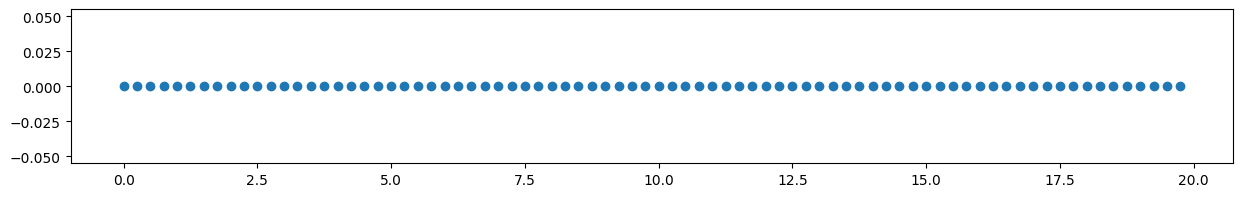

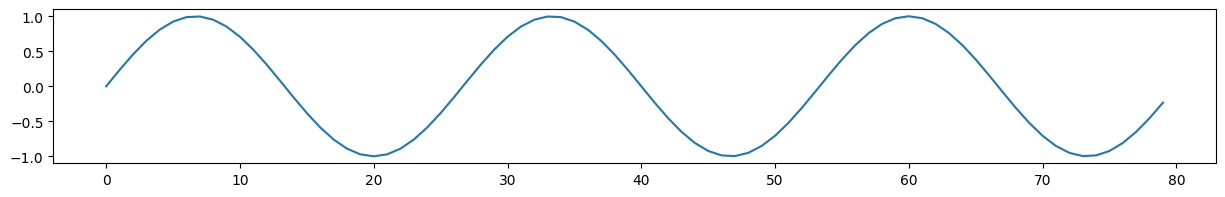

In [82]:
t1 = np.arange(N) / fs
y1 = np.sin(2*np.pi*f*t1)

plt.figure(figsize = (15,2))
plt.scatter(t1, np.zeros_like(y1))
plt.show()

y1 = np.sin(2*np.pi*f*t1)
plt.figure(figsize = (15,2))
plt.plot(y1)
plt.show()

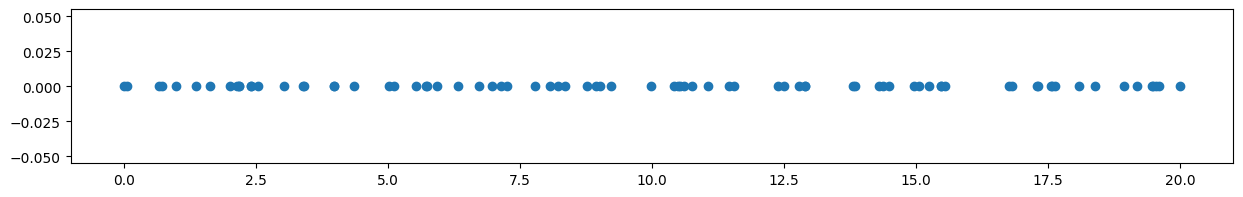

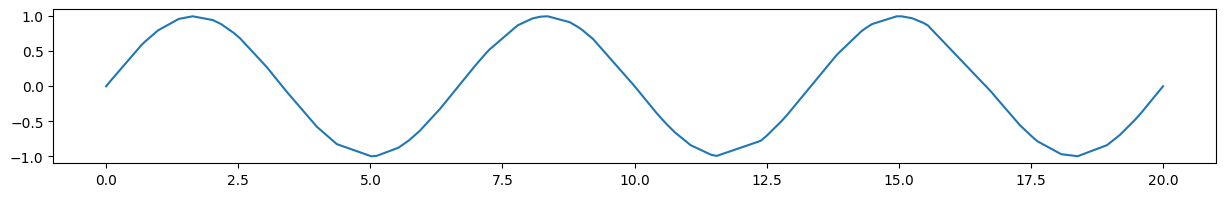

In [83]:
t2 = np.arange(N) / fs + np.random.normal(1, 0.5, size=N)
t2 = np.interp(t2, (t2.min(), t2.max()), (0, N/fs))
t2 = np.sort(t2)
y2 = np.sin(2*np.pi*f*t2)

plt.figure(figsize = (15,2))
plt.scatter(t2, np.zeros_like(y2))

plt.figure(figsize = (15,2))
plt.plot(t2, y2)
plt.show()

In [84]:
np.interp(2, [1, 3], [10, 30])

20.0

In [85]:
np.interp([1, 2 ,3],[1, 3], [10, 30])

array([10., 20., 30.])

In [86]:
np.interp(1.5, [1, 2, 3], [10, 30, 90])

20.0

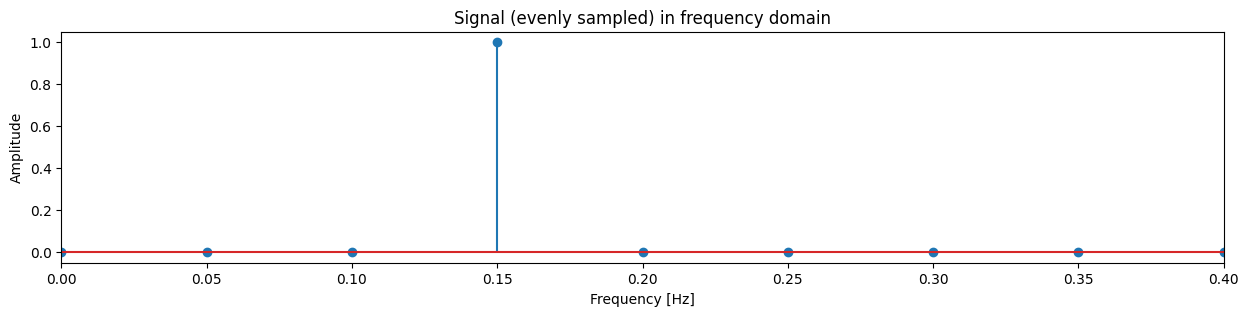

In [87]:
f_vec = np.fft.rfftfreq(N, d=1 / fs)
dft_result = np.fft.rfft(y1)

amplitude_spectrum = np.abs(dft_result) / N
amplitude_spectrum[1:-1] *= 2

plt.figure(figsize=(15, 3))
plt.stem(f_vec, amplitude_spectrum)
plt.xlim(0, 0.4)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Amplitude")
plt.title("Signal (evenly sampled) in frequency domain")
plt.show()

In [88]:
f_vec

array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
       0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  , 1.05,
       1.1 , 1.15, 1.2 , 1.25, 1.3 , 1.35, 1.4 , 1.45, 1.5 , 1.55, 1.6 ,
       1.65, 1.7 , 1.75, 1.8 , 1.85, 1.9 , 1.95, 2.  ])

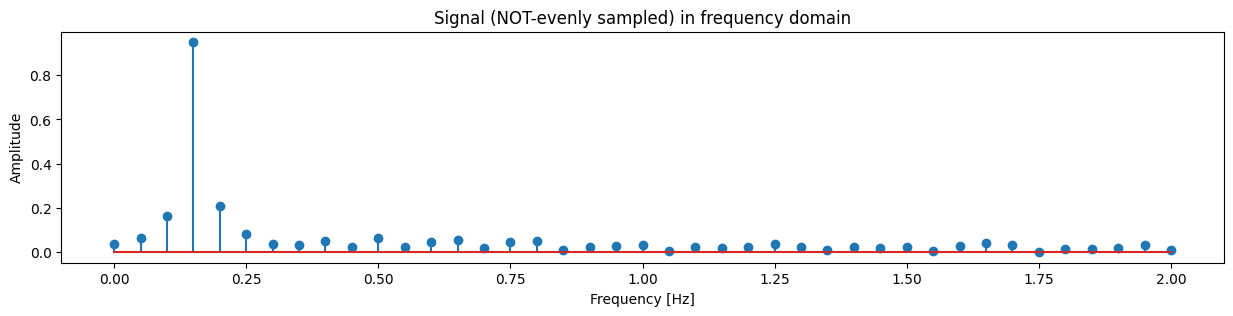

In [89]:
f_vec = np.fft.rfftfreq(N, d=1 / fs)
dft_result = np.fft.rfft(y2)

amplitude_spectrum = np.abs(dft_result) / N
amplitude_spectrum[1:-1] *= 2

plt.figure(figsize=(15, 3))
plt.stem(f_vec, amplitude_spectrum)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Amplitude")
plt.title("Signal (NOT-evenly sampled) in frequency domain")
plt.show()

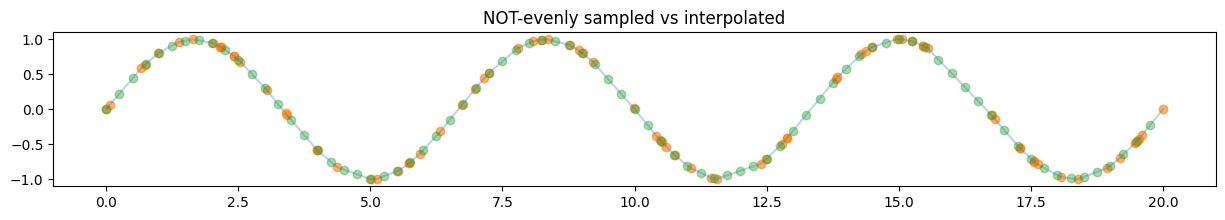

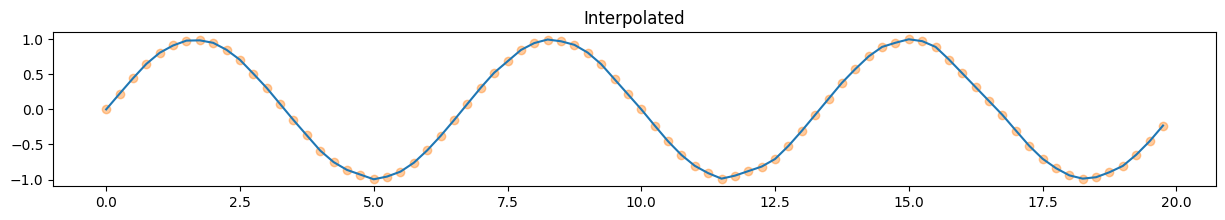

In [90]:
y3 = np.interp(t1, t2, y2)

plt.figure(figsize = (15,2))
plt.plot(t2, y2, alpha=0.3)
plt.scatter(t2, y2, color="tab:orange", alpha=0.6)
plt.scatter(t1, y3, color="tab:green", alpha=0.4)
plt.title("NOT-evenly sampled vs interpolated")
plt.show()

plt.figure(figsize = (15,2))
plt.plot(t1, y3)
plt.title("Interpolated")
plt.scatter(t1, y3, color="tab:orange", alpha=0.4)
plt.show()

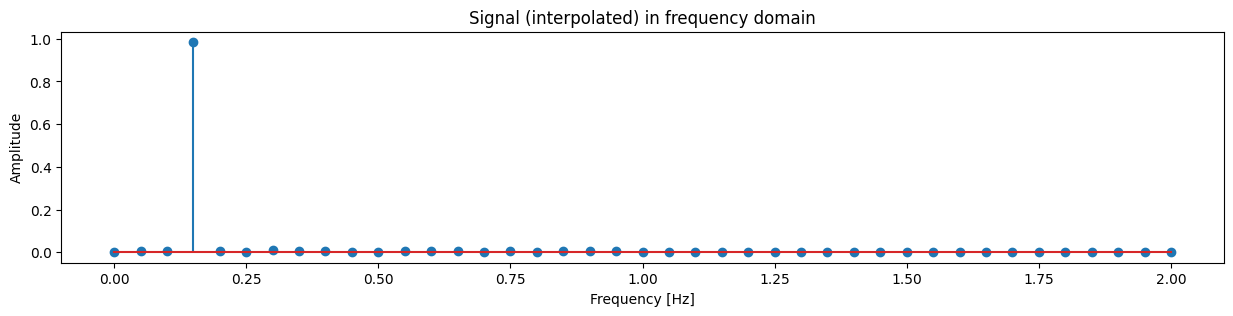

In [91]:
f_vec = np.fft.rfftfreq(N, d=1 / fs)
dft_result = np.fft.rfft(y3)

amplitude_spectrum = np.abs(dft_result) / N
amplitude_spectrum[1:-1] *= 2

plt.figure(figsize=(15, 3))
plt.stem(f_vec, amplitude_spectrum)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Amplitude")
plt.title("Signal (interpolated) in frequency domain")
plt.show()